In [1]:
import utils
import pandas as pd
from matplotlib import pyplot as plt

In [2]:
data_file = "chocolate.json"
objdata = utils.load_chocodata(data_file)

In [3]:
df_choco = utils.build_chocodataframe(objdata)
df_choco

,2025-06-16 (e3e70682),2025-07-04 (eb1167b3),2025-07-04 (f728b4fa),2025-09-20 (f7c1bd87),2025-09-21 (23a7711a),2025-09-21 (e443df78),2025-11-07 (b4862b21),2025-11-08 (1846d424),2025-11-08 (fcbd04c3),2025-11-21 (259f4329),2025-12-08 (12e0c8b2),2025-12-08 (5487ce1e),2025-12-22 (5a921187),2026-02-24 (a3f2c9bf),2026-03-21 (8d723104),2026-05-02 (85776e9a),2026-05-02 (eb2083e6),2026-06-06 (17e0aa3c),2026-07-31 (b5d32b16)
Tablet,,,,,,,,,,,,,,,,,,,
Dessert 70% Cacao Intense,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
Cooking Extra Fondant,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
Création caramel,1,0,0,0,0,0,0,0,0,1,1,0,1,1,0,0,0,0,0
Création crème brûlée,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,1,1
Création entremets noisette,0,0,0,1,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0
Création Irish coffee,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Création Menthe Frappée,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
Création praliné feuilleté,0,0,1,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0
Création rocher blanc,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0


In [4]:
df_ident = utils.build_identitydataframe(objdata)
df_ident

,Retail (€),Weight (g)
Tablet,,
Dessert 70% Cacao Intense,4.99,200.0
Cooking Extra Fondant,4.99,200.0
Création caramel,4.49,150.0
Création crème brûlée,4.49,150.0
Création entremets noisette,4.49,150.0
Création Irish coffee,4.49,150.0
Création Menthe Frappée,4.49,150.0
Création praliné feuilleté,4.49,150.0
Création rocher blanc,4.49,150.0


In [5]:
df_event = utils.build_eventdataframe(objdata)
df_event

,Date,Session,Price (€),Weight (g)
id,,,,
2025-06-16 (e3e70682),16/06/2025,e3e70682,15.90,0.995
2025-07-04 (f728b4fa),4/7/2025,f728b4fa,15.90,1.045
2025-07-04 (eb1167b3),4/7/2025,eb1167b3,15.90,1.000
2025-09-20 (f7c1bd87),20/9/2025,f7c1bd87,15.90,1.000
2025-09-21 (e443df78),21/9/2025,e443df78,15.90,1.000
2025-09-21 (23a7711a),21/9/2025,23a7711a,15.90,1.000
2025-11-08 (1846d424),8/11/2025,1846d424,15.90,1.050
2025-11-08 (fcbd04c3),8/11/2025,fcbd04c3,15.90,1.000
2025-11-07 (b4862b21),7/11/2025,b4862b21,15.90,1.000


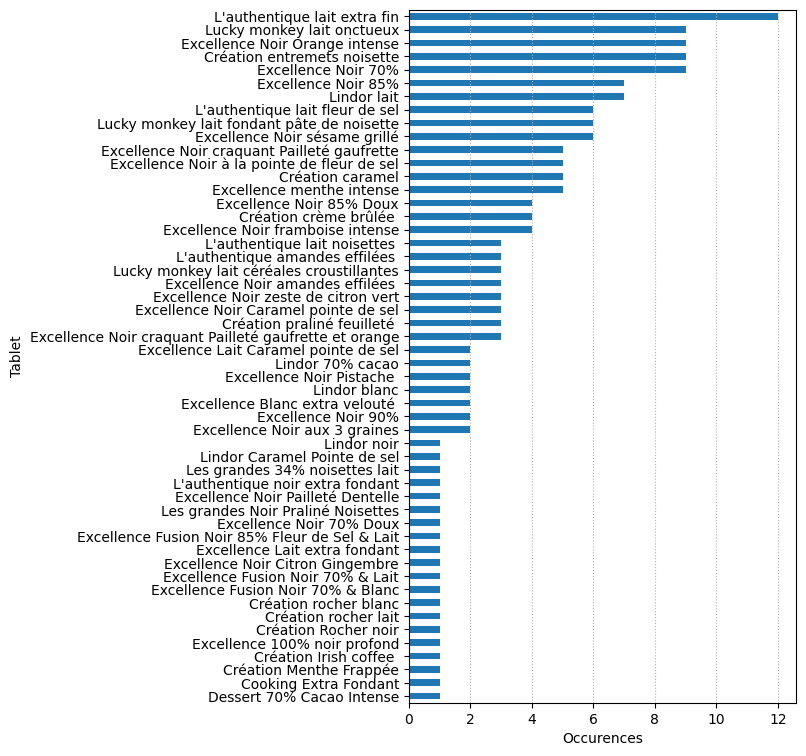

In [6]:
h, ax = plt.subplots(figsize=(5,9))
df_choco.sum(axis=1).sort_values().plot(ax=ax, kind="barh", xlabel="Occurences")
ax.xaxis.grid(True, which='major', ls=':')
plt.show()

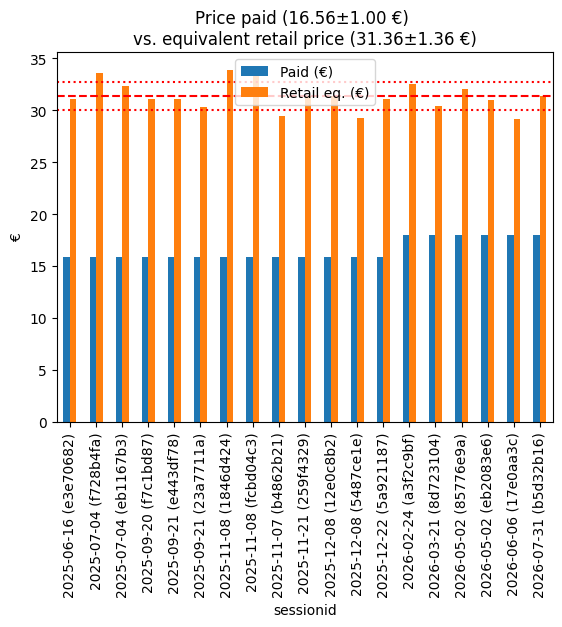

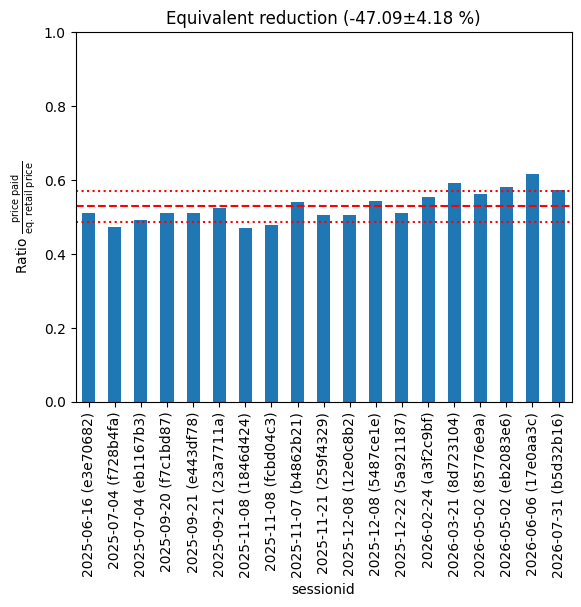

In [7]:
tabular_data = {
    "sessionid" : [],
    "Paid (€)" : [],
    "Retail eq. (€)" : []
}
for sessionid in df_event.index:
    paid = df_event.at[sessionid,"Price (€)"]
    got = df_choco[sessionid]
    retail_eq = (df_ident.loc[got.index,"Retail (€)"] * got).sum()
    tabular_data["sessionid"].append(sessionid)
    tabular_data["Paid (€)"].append(paid)
    tabular_data["Retail eq. (€)"].append(retail_eq)

df = pd.DataFrame(tabular_data).set_index("sessionid")

av_paid = df["Paid (€)"].mean()
sd_paid = df["Paid (€)"].std()
av_equi = df["Retail eq. (€)"].mean()
sd_equi = df["Retail eq. (€)"].std()
av_ratio = (df["Paid (€)"] / df["Retail eq. (€)"]).mean()
sd_ratio = (df["Paid (€)"] / df["Retail eq. (€)"]).std()

# ============================================================

h,a = plt.subplots()
df.plot(
    ax=a,
    kind="bar",
    title=f"Price paid ({av_paid:.2f}±{sd_paid:.2f} €) \nvs. equivalent retail price ({av_equi:.2f}±{sd_equi:.2f} €)",
    ylabel="€"
)
a.axhline(
    av_equi,
    color='red',
    ls="--"
)
a.axhline(
    av_equi + sd_equi,
    color='red',
    ls=":"
)
a.axhline(
    av_equi - sd_equi,
    color='red',
    ls=":"
)
plt.show()

# ============================================================

h,a = plt.subplots()
(df["Paid (€)"] / df["Retail eq. (€)"]).plot(
    ax=a,
    kind="bar", 
    ylim=(0,1), 
    title=f"Equivalent reduction (-{100-av_ratio*100:.2f}±{sd_ratio*100:.2f} %)",
    ylabel=r"Ratio $\frac{\text{price paid}}{\text{eq. retail price}}$"
)
a.axhline(
    av_ratio,
    color='red',
    ls="--"
)
a.axhline(
    av_ratio + sd_ratio,
    color='red',
    ls=":"
)
a.axhline(
    av_ratio - sd_ratio,
    color='red',
    ls=":"
)
plt.show()